# DigitRescue — Corrected Denoising Autoencoder (Colab T4 GPU)

This notebook retrains **only** `digitrescue_autoencoder.keras` on Google Colab GPU while:
- Leaving `digitrescue_cnn.keras` completely unchanged.
- Splitting the 60,000 MNIST training images into **54,000 train / 6,000 validation** (eliminating test-set leakage).
- Keeping all **10,000 MNIST test images** strictly held out for final evaluation.
- Preserving all five corruption types and exact parameters from `AutoDigit.ipynb`.
- Fixing the MSE + Sigmoid collapse via `binary_crossentropy`, `BatchNormalization`, `clipnorm=1.0`, and global shuffling.

**Before running:** In Colab, select **Runtime -> Change runtime type -> T4 GPU**.


## 1. GPU Verification (TensorFlow + NVIDIA SMI)


In [1]:
import subprocess
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

try:
    smi = subprocess.run(["nvidia-smi"], capture_output=True, text=True, check=False)
    print(smi.stdout if smi.returncode == 0 else "nvidia-smi not available.")
except FileNotFoundError:
    print("nvidia-smi command not found.")

gpus = tf.config.list_physical_devices("GPU")
print("Detected TensorFlow GPUs:", gpus)

if not gpus:
    raise RuntimeError(
        "No GPU detected by TensorFlow! "
        "Go to Runtime -> Change runtime type -> Hardware accelerator -> T4 GPU, then restart and re-run."
    )

for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)
    details = tf.config.experimental.get_device_details(gpu)
    print("Active GPU:", details.get("device_name", gpu.name))

TensorFlow version: 2.21.0
Tue Nov 10 11:44:16 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+--------------------

## 2. Mount Google Drive & Configure Paths
Make sure `digitrescue_cnn.keras` is in `/content/drive/MyDrive/DigitRescue/` (or upload it when prompted if missing). Existing Drive backups are never overwritten.


In [2]:
import os
import shutil
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

DRIVE_DIR = Path("/content/drive/MyDrive/DigitRescue")
DRIVE_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_DIR = DRIVE_DIR / "retrained_v2"
RESULTS_DIR = OUTPUT_DIR / "results"
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
BACKUP_DIR = DRIVE_DIR / "backups"

for d in (OUTPUT_DIR, RESULTS_DIR, CHECKPOINT_DIR, BACKUP_DIR):
    d.mkdir(parents=True, exist_ok=True)

CNN_PATH = DRIVE_DIR / "digitrescue_cnn.keras"
if not CNN_PATH.exists():
    print(f"CNN model not found at {CNN_PATH}. Please upload digitrescue_cnn.keras:")
    from google.colab import files
    uploaded = files.upload()
    if "digitrescue_cnn.keras" in uploaded:
        shutil.move("digitrescue_cnn.keras", CNN_PATH)
    else:
        raise FileNotFoundError("digitrescue_cnn.keras is required for final evaluation.")

# Preserve any existing autoencoder on Drive before saving new artifacts
existing_drive_ae = DRIVE_DIR / "digitrescue_autoencoder.keras"
backup_drive_ae = BACKUP_DIR / "digitrescue_autoencoder_before_v2.keras"
if existing_drive_ae.exists() and not backup_drive_ae.exists():
    shutil.copy2(existing_drive_ae, backup_drive_ae)
    print("Backed up existing Drive autoencoder to:", backup_drive_ae)

AE_FINAL_PATH = OUTPUT_DIR / "digitrescue_autoencoder.keras"
AE_CKPT_PATH = CHECKPOINT_DIR / "best_autoencoder.keras"

print("CNN path (read-only):", CNN_PATH)
print("Output dir:", OUTPUT_DIR)

Mounted at /content/drive
Backed up existing Drive autoencoder to: /content/drive/MyDrive/DigitRescue/backups/digitrescue_autoencoder_before_v2.keras
CNN path (read-only): /content/drive/MyDrive/DigitRescue/digitrescue_cnn.keras
Output dir: /content/drive/MyDrive/DigitRescue/retrained_v2


## 3. Load MNIST & Create Leak-Free 54,000 / 6,000 Train-Val Split
All 10,000 MNIST test images (`x_test`, `y_test`) remain completely untouched until Section 8.


In [3]:
import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

(x_train_full, y_train_full), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Deterministic 90/10 split of the 60,000 training images ONLY
split_rng = np.random.default_rng(42)
perm_idx = split_rng.permutation(len(x_train_full))
train_idx = perm_idx[:54000]
val_idx = perm_idx[54000:]

assert len(train_idx) == 54000
assert len(val_idx) == 6000
assert len(set(train_idx).intersection(set(val_idx))) == 0
assert len(x_test) == 10000

train_clean = x_train_full[train_idx]
val_clean = x_train_full[val_idx]

print("train_clean:", train_clean.shape)
print("val_clean:  ", val_clean.shape)
print("x_test (held-out):", x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
train_clean: (54000, 28, 28)
val_clean:   (6000, 28, 28)
x_test (held-out): (10000, 28, 28)


## 4. Five Corruption Generators & Classical Preprocessing (Exact Notebook Parameters)


In [4]:
NOISE_TYPES = ["gaussian", "salt_pepper", "blur", "fading", "erasure"]

def create_corrupted(images, noise_type, seed=42):
    rng = np.random.default_rng(seed)
    x = images.astype(np.float32) / 255.0

    if noise_type == "gaussian":
        noise = rng.normal(0, 0.4, x.shape)
        x = np.clip(x + noise, 0, 1)
    elif noise_type == "salt_pepper":
        r = rng.random(x.shape)
        x[r < 0.075] = 0
        x[(r >= 0.075) & (r < 0.15)] = 1
    elif noise_type == "blur":
        x = gaussian_filter(x, sigma=(0, 1.3, 1.3))
    elif noise_type == "fading":
        factors = rng.uniform(0.32, 0.48, (len(x), 1, 1))
        smooth = gaussian_filter(rng.random(x.shape), sigma=(0, 4, 4))
        low = smooth.min(axis=(1, 2), keepdims=True)
        high = smooth.max(axis=(1, 2), keepdims=True)
        smooth = (smooth - low) / (high - low + 1e-8)
        x = x * factors * (0.5 + 0.5 * smooth)
    elif noise_type == "erasure":
        out = images.copy()
        for i in range(len(out)):
            ys, xs = np.nonzero(images[i] > 80)
            if len(ys) == 0:
                continue
            for _ in range(2):
                k = rng.integers(len(ys))
                h = rng.integers(4, 7)
                w = rng.integers(4, 7)
                top = max(0, ys[k] - h // 2)
                left = max(0, xs[k] - w // 2)
                out[i, top:top + h, left:left + w] = 0
        return out
    else:
        raise ValueError(f"Unknown noise type: {noise_type}")

    return np.clip(x * 255, 0, 255).astype(np.uint8)


clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(4, 4))

def preprocess_image(image, noise_type):
    image = cv2.resize(image, (28, 28))
    if noise_type == "salt_pepper":
        image = cv2.medianBlur(image, 3)
    elif noise_type == "gaussian":
        image = cv2.GaussianBlur(image, (3, 3), 0)
    elif noise_type == "blur":
        blurred = cv2.GaussianBlur(image, (0, 0), 1.0)
        image = cv2.addWeighted(image, 1.5, blurred, -0.5, 0)
    elif noise_type in ["fading", "erasure"]:
        image = clahe.apply(image)
    return image


train_noisy_parts, val_noisy_parts = [], []
for i, noise in enumerate(NOISE_TYPES):
    print("Generating train/val corruptions:", noise)
    train_noisy_parts.append(create_corrupted(train_clean, noise, seed=42 + i))
    val_noisy_parts.append(create_corrupted(val_clean, noise, seed=242 + i))

noisy_all = np.concatenate(train_noisy_parts, axis=0)
clean_all = np.tile(train_clean, (len(NOISE_TYPES), 1, 1))

# Global shuffle across all 5 corruption types
shuffle_perm = np.random.default_rng(42).permutation(len(noisy_all))
noisy_all = noisy_all[shuffle_perm]
clean_all = clean_all[shuffle_perm]

val_noisy_all = np.concatenate(val_noisy_parts, axis=0)
val_clean_all = np.tile(val_clean, (len(NOISE_TYPES), 1, 1))

print("Total training pairs (54k x 5):  ", len(noisy_all))
print("Total validation pairs (6k x 5): ", len(val_noisy_all))

Generating train/val corruptions: gaussian
Generating train/val corruptions: salt_pepper
Generating train/val corruptions: blur
Generating train/val corruptions: fading
Generating train/val corruptions: erasure
Total training pairs (54k x 5):   270000
Total validation pairs (6k x 5):  30000


## 5. Efficient `tf.data` Pipeline for T4 GPU


In [5]:
AUTOTUNE = tf.data.AUTOTUNE
BATCH_SIZE = 256

def normalize_pair(noisy_img, clean_img):
    noisy_img = tf.cast(noisy_img, tf.float32) / 255.0
    clean_img = tf.cast(clean_img, tf.float32) / 255.0
    return tf.expand_dims(noisy_img, -1), tf.expand_dims(clean_img, -1)

train_ds = (
    tf.data.Dataset.from_tensor_slices((noisy_all, clean_all))
    .map(normalize_pair, num_parallel_calls=AUTOTUNE)
    .cache()
    .shuffle(50000, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_ds = (
    tf.data.Dataset.from_tensor_slices((val_noisy_all, val_clean_all))
    .map(normalize_pair, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .cache()
    .prefetch(AUTOTUNE)
)

print("Datasets ready for T4 GPU training.")

Datasets ready for T4 GPU training.


## 6. Build & Train Corrected Denoising Autoencoder
Uses `BatchNormalization`, `binary_crossentropy`, `Adam(lr=1e-3, clipnorm=1.0)`, `ModelCheckpoint`, `EarlyStopping`, and `ReduceLROnPlateau`.


In [6]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

inputs = Input(shape=(28, 28, 1))

# Encoder
x = Conv2D(32, (3, 3), activation="relu", padding="same")(inputs)
x = BatchNormalization()(x)
x = MaxPooling2D((2, 2), padding="same")(x)

x = Conv2D(64, (3, 3), activation="relu", padding="same")(x)
x = BatchNormalization()(x)
x = MaxPooling2D((2, 2), padding="same")(x)

# Decoder
x = Conv2D(64, (3, 3), activation="relu", padding="same")(x)
x = BatchNormalization()(x)
x = UpSampling2D((2, 2))(x)

x = Conv2D(32, (3, 3), activation="relu", padding="same")(x)
x = BatchNormalization()(x)
x = UpSampling2D((2, 2))(x)

outputs = Conv2D(1, (3, 3), activation="sigmoid", padding="same")(x)

digitrescue_autoencoder = Model(
    inputs, outputs, name="DigitRescue_Denoising_Autoencoder"
)

digitrescue_autoencoder.compile(
    optimizer=Adam(learning_rate=1e-3, clipnorm=1.0),
    loss="binary_crossentropy",
    metrics=["mae", "mse"],
)

digitrescue_autoencoder.summary()

callbacks = [
    ModelCheckpoint(
        filepath=str(AE_CKPT_PATH),
        monitor="val_loss",
        save_best_only=True,
        verbose=1,
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1,
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-5,
        verbose=1,
    ),
]

dae_history = digitrescue_autoencoder.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks,
)

digitrescue_autoencoder.save(AE_FINAL_PATH)
print("Final autoencoder saved to:", AE_FINAL_PATH)

Model: "DigitRescue_Denoising_Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 7, 7, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 14, 14, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 75,265 (294.00 KB)

 Trainable params: 74,881 (292.50 KB)

 Non-trainable params: 384 (1.50 KB)

Epoch 1/20
1055/1055 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.1984 - mae: 0.1074 - mse: 0.0392
Epoch 1: val_loss improved from None to 0.08722, saving model to /content/drive/MyDrive/DigitRescue/retrained_v2/checkpoints/best_autoencoder.keras

Epoch 1: finished saving model to /content/drive/MyDrive/DigitRescue/retrained_v2/checkpoints/best_autoencoder.keras
1055/1055 ━━━━━━━━━━━━━━━━━━━━ 57s 34ms/step - loss: 0.1194 - mae: 0.0525 - mse: 0.0165 - val_loss: 0.0872 - val_mae: 0.0298 - val_mse: 0.0081 - learning_rate: 0.0010
Epoch 2/20
1052/1055 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0835 - mae: 0.0266 - mse: 0.0070
Epoch 2: val_loss improved from 0.08722 to 0.08239, saving model to /content/drive/MyDrive/DigitRescue/retrained_v2/checkpoints/best_autoencoder.keras

Epoch 2: finished saving model to /content/drive/MyDrive/DigitRescue/retrained_v2/checkpoints/best_autoencoder.keras
1055/1055 ━━━━━━━━━━━━━━━━━━━━ 15s 14ms/step - loss: 0.0825 - mae: 0.0259 - mse: 0.0067 - val_loss: 0.

## 7. Training Curves & 20-Image Sanity Verification


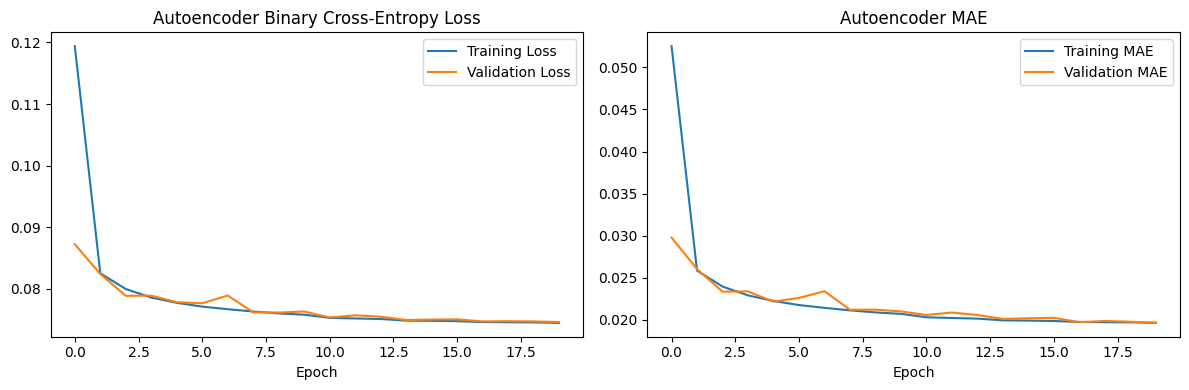

AE clean output range: min=0.0000, max=0.9979, std_across_images=0.1688
20-image Clean CNN accuracy: 100.0%
20-image AE(Clean)->CNN accuracy: 100.0%
20-image Gaussian Noisy CNN accuracy: 85.0%
20-image AE(Gaussian)->CNN accuracy: 95.0%


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(dae_history.history["loss"], label="Training Loss")
axes[0].plot(dae_history.history["val_loss"], label="Validation Loss")
axes[0].set_title("Autoencoder Binary Cross-Entropy Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(dae_history.history["mae"], label="Training MAE")
axes[1].plot(dae_history.history["val_mae"], label="Validation MAE")
axes[1].set_title("Autoencoder MAE")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

# Load unchanged CNN (read-only) and run 20-image check
cnn = tf.keras.models.load_model(CNN_PATH)
x20 = (x_test[:20].astype("float32") / 255.0).reshape(-1, 28, 28, 1)
y20 = y_test[:20]

ae_clean_out = digitrescue_autoencoder.predict(x20, verbose=0)
clean_pred = np.argmax(cnn.predict(x20, verbose=0), axis=1)
ae_clean_pred = np.argmax(cnn.predict(ae_clean_out, verbose=0), axis=1)

print(f"AE clean output range: min={ae_clean_out.min():.4f}, max={ae_clean_out.max():.4f}, std_across_images={np.std(ae_clean_out, axis=0).mean():.4f}")
print(f"20-image Clean CNN accuracy: {np.mean(clean_pred == y20)*100:.1f}%")
print(f"20-image AE(Clean)->CNN accuracy: {np.mean(ae_clean_pred == y20)*100:.1f}%")

noisy20_gauss = create_corrupted(x_test[:20], "gaussian", seed=142).astype("float32") / 255.0
noisy20_gauss_4d = noisy20_gauss.reshape(-1, 28, 28, 1)
ae_gauss_out = digitrescue_autoencoder.predict(noisy20_gauss_4d, verbose=0)
noisy_gauss_pred = np.argmax(cnn.predict(noisy20_gauss_4d, verbose=0), axis=1)
ae_gauss_pred = np.argmax(cnn.predict(ae_gauss_out, verbose=0), axis=1)
print(f"20-image Gaussian Noisy CNN accuracy: {np.mean(noisy_gauss_pred == y20)*100:.1f}%")
print(f"20-image AE(Gaussian)->CNN accuracy: {np.mean(ae_gauss_pred == y20)*100:.1f}%")

## 8. Final Held-Out Evaluation (All 10,000 MNIST Test Images) & Save CSVs to Google Drive


Clean Test Accuracy (10,000 images): 99.19%
[gaussian   ] Noisy=85.10%, Preprocessed=96.65%, AI Restored=98.14% | PSNR: 11.01 -> 20.99 dB
[salt_pepper] Noisy=88.95%, Preprocessed=98.11%, AI Restored=98.75% | PSNR: 11.42 -> 23.49 dB
[blur       ] Noisy=97.78%, Preprocessed=98.32%, AI Restored=99.01% | PSNR: 16.81 -> 26.84 dB
[fading     ] Noisy=98.36%, Preprocessed=99.06%, AI Restored=99.06% | PSNR: 12.48 -> 27.60 dB
[erasure    ] Noisy=84.96%, Preprocessed=84.97%, AI Restored=98.13% | PSNR: 15.78 -> 22.54 dB


,Corruption,Noisy Accuracy (%),Preprocessed Accuracy (%),AI Restored Accuracy (%)
0,gaussian,85.10,96.65,98.14
1,salt_pepper,88.95,98.11,98.75
2,blur,97.78,98.32,99.01
3,fading,98.36,99.06,99.06
4,erasure,84.96,84.97,98.13


,Noisy PSNR,Restored PSNR
,,
gaussian,11.014,20.990
salt_pepper,11.419,23.489
blur,16.813,26.838
fading,12.478,27.596
erasure,15.783,22.535


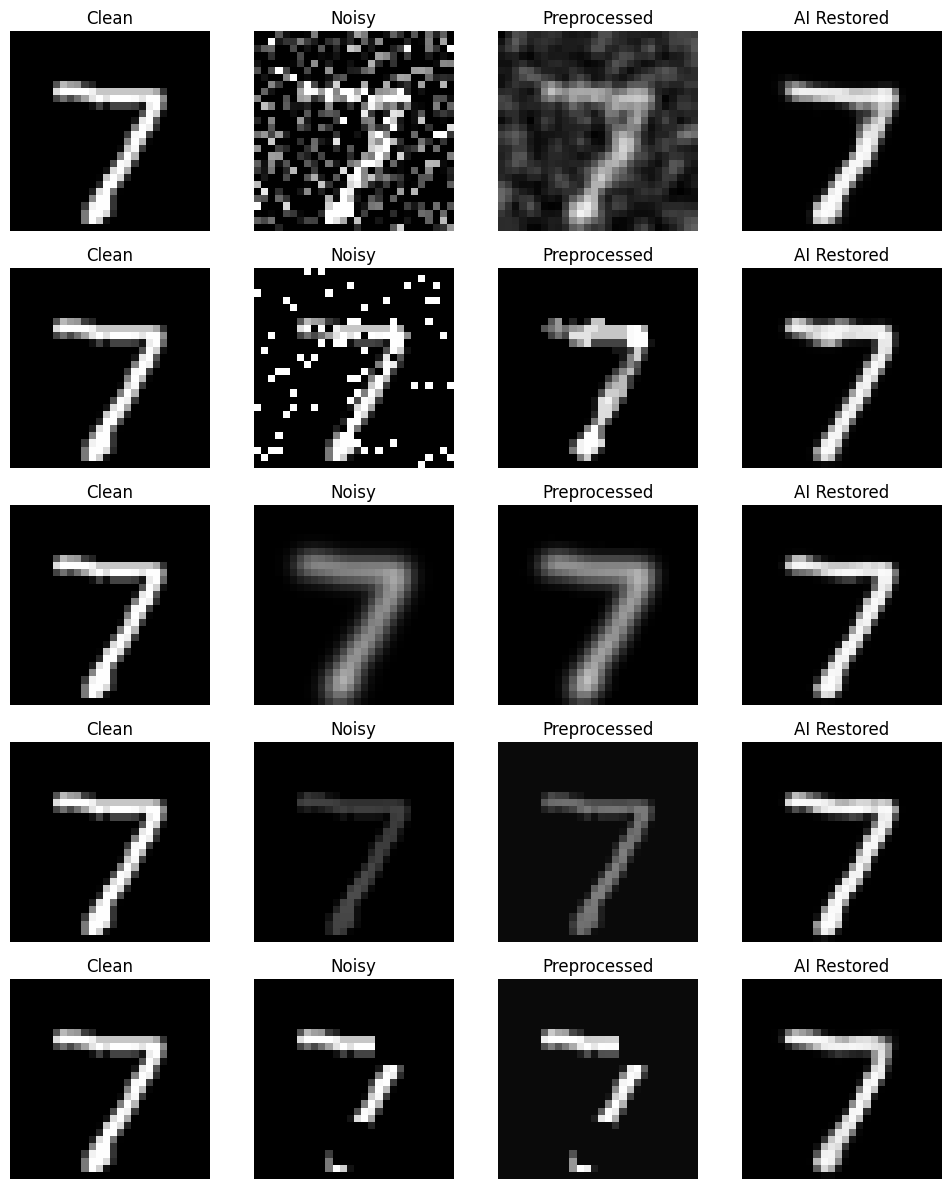

Saved all artifacts and zip package to: /content/drive/MyDrive/DigitRescue/retrained_v2/DigitRescue_Retrained_Artifacts.zip


In [8]:
def calculate_accuracy(images, labels):
    X = (images.astype("float32") / 255.0).reshape(-1, 28, 28, 1)
    preds = cnn.predict(X, batch_size=256, verbose=0)
    return float(np.mean(np.argmax(preds, axis=1) == labels) * 100.0)


def calculate_psnr(clean, restored):
    clean = clean.astype("float32") / 255.0
    restored = restored.astype("float32") / 255.0
    mse = np.mean((clean - restored) ** 2)
    if mse == 0:
        return float("inf")
    return float(10.0 * np.log10(1.0 / mse))


clean_accuracy = calculate_accuracy(x_test, y_test)
print(f"Clean Test Accuracy (10,000 images): {clean_accuracy:.2f}%")

acc_rows = []
psnr_rows = []
visual_samples = {}

for i, noise in enumerate(NOISE_TYPES):
    noisy_test = create_corrupted(x_test, noise, seed=142 + i)

    processed_test = np.empty_like(noisy_test)
    for j in range(len(noisy_test)):
        processed_test[j] = preprocess_image(noisy_test[j], noise)

    noisy_in = (noisy_test.astype("float32") / 255.0).reshape(-1, 28, 28, 1)
    restored = digitrescue_autoencoder.predict(noisy_in, batch_size=256, verbose=0)
    restored_u8 = np.clip(restored[:, :, :, 0] * 255.0, 0, 255).astype("uint8")

    noisy_acc = calculate_accuracy(noisy_test, y_test)
    proc_acc = calculate_accuracy(processed_test, y_test)
    rest_acc = calculate_accuracy(restored_u8, y_test)

    noisy_psnr = calculate_psnr(x_test, noisy_test)
    rest_psnr = calculate_psnr(x_test, restored_u8)

    print(
        f"[{noise:11s}] Noisy={noisy_acc:5.2f}%, Preprocessed={proc_acc:5.2f}%, "
        f"AI Restored={rest_acc:5.2f}% | PSNR: {noisy_psnr:.2f} -> {rest_psnr:.2f} dB"
    )

    acc_rows.append({
        "Corruption": noise,
        "Noisy Accuracy (%)": noisy_acc,
        "Preprocessed Accuracy (%)": proc_acc,
        "AI Restored Accuracy (%)": rest_acc,
    })
    psnr_rows.append({
        "": noise,
        "Noisy PSNR": noisy_psnr,
        "Restored PSNR": rest_psnr,
    })
    visual_samples[noise] = (noisy_test[0], processed_test[0], restored_u8[0])

# Save all CSVs to Google Drive
df_acc = pd.DataFrame(acc_rows)
df_psnr = pd.DataFrame(psnr_rows).set_index("")
df_summary = pd.DataFrame([{
    "metric": "Clean Accuracy",
    "accuracy_percent": clean_accuracy,
    "test_images": int(len(y_test)),
}])
df_hist = pd.DataFrame(dae_history.history)

df_acc.to_csv(RESULTS_DIR / "accuracy_comparison.csv", index=False)
df_psnr.to_csv(RESULTS_DIR / "psnr_comparison.csv")
df_summary.to_csv(RESULTS_DIR / "summary_metrics.csv", index=False)
df_hist.to_csv(RESULTS_DIR / "autoencoder_training_history.csv", index_label="epoch")

display(df_acc.round(2))
display(df_psnr.round(3))

# Visual preview across all 5 corruption types (test image index 0)
fig, axes = plt.subplots(5, 4, figsize=(10, 12))
for row, noise in enumerate(NOISE_TYPES):
    imgs = [x_test[0], *visual_samples[noise]]
    titles = ["Clean", "Noisy", "Preprocessed", "AI Restored"]
    for col in range(4):
        axes[row, col].imshow(imgs[col], cmap="gray", vmin=0, vmax=255)
        axes[row, col].set_title(titles[col])
        axes[row, col].axis("off")
    axes[row, 0].set_ylabel(noise)
plt.tight_layout()
plt.show()

# Package model + CSVs into a single zip on Google Drive for easy download
import zipfile
zip_out = OUTPUT_DIR / "DigitRescue_Retrained_Artifacts.zip"
with zipfile.ZipFile(zip_out, "w", zipfile.ZIP_DEFLATED) as zf:
    zf.write(AE_FINAL_PATH, arcname="digitrescue_autoencoder.keras")
    for csv_file in RESULTS_DIR.glob("*.csv"):
        zf.write(csv_file, arcname=f"results/{csv_file.name}")

print("Saved all artifacts and zip package to:", zip_out)